In [1]:
from common import *

### Metadynamics UpU

In [2]:
path = PROJECT_DIR / 'metad/op_mMg_tip3p'

Unbound: [     0 143630   1240  21480 138770 144680 140890 139370  24860  91260]
Outer: [ 76440 175270 131560  72500 160280  46200 122000 155850 156090   7200]
Transition: [ 71180  86200  87160 153380  65890 115950  12760 175720  77640  28440]
Inner: [123770 147660 122230 190400  64780  68180  59380   4920 196050  11000]
Other mono: [126680 126120 128680 127610  80050  79170 125980 126670 125070 126060]
Other bi: [ 27710  81990 167830  78070 168030 181010 181600 167590  27560 182050]


/tmp/ipykernel_316532/1236607698.py:29: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)


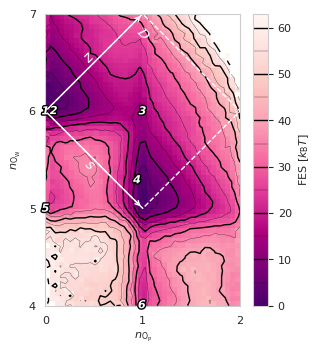

In [3]:
fig, ax = plt.subplots(figsize=(8.7*cm, 8.7*cm), layout="compressed")

colvar = read_plumed(f'{path}/COLVAR')
bins = np.linspace(0, 2, 41), np.linspace(4, 7, 61)

bias = colvar['metad.bias']  # kJ/mol
weights = np.exp(bias/RT)

# Remove nop == 0
x, y = colvar['nop'], colvar['now']
weights[x <= 0] = 0

# Frames for rendering
def get_frame(*d):
    frames = np.argsort(np.linalg.norm(np.stack(d), axis=0))
    return frames[frames % 10 == 0][:10]
print("Unbound:", get_frame(x > 0, y - 6))
print("Outer:", get_frame(x == 0, y - 6))
print("Transition:", get_frame(x - 1, y - 6))
print("Inner:", get_frame(x - 1, y - 5))
print("Other mono:", get_frame(x - 0, y - 5))
print("Other bi:", get_frame(x - 1, y - 4))

for i, t in enumerate([24860, 76440, 71180, 147660, 80050, 27710]):
    txt = ax.text(x[t], y[t], i+1, color='white', fontweight='bold', fontstyle='italic', zorder=10, va='center', ha='center')
    txt.set_path_effects([PathEffects.withStroke(linewidth=2, foreground='k')])

ρ_avg, x_edges, y_edges = np.histogram2d(x, y, bins=bins, density=True, weights=weights)
fes = -np.log(ρ_avg)
fes -= finitemin(fes)

extent = [*x_edges[[0, -1]], *y_edges[[0, -1]]]
levels = np.arange(0, finitemax(fes), 5)

im = ax.imshow(fes.T, extent=extent, origin='lower', aspect=1, cmap='RdPu_r')
cf = ax.contour(fes.T, colors=['black'], linewidths=[1, 0.2], extent=extent, levels=levels)
cbar = plt.colorbar(im)
cbar.add_lines(cf)
cbar.set_label("FES [$k_\mathrm{B}T$]")

ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(False)
ax.plot([0, 1, 2, 1, 0], [6, 7, 6, 5, 6], color='white', linestyle='dashed', linewidth=1)
ax.annotate("", xy=(1, 5), xytext=(0, 6), color='white', zorder=20, arrowprops=dict(arrowstyle="->"))
ax.annotate("", xy=(1, 7), xytext=(0, 6), color='white', zorder=20, arrowprops=dict(arrowstyle="->"))
ax.text(0.5, 5.5, r'$s$', rotation=-45, color='white', size=10, va='top', ha='center', rotation_mode='anchor')
ax.text(0.5, 6.5, r'$z$', rotation=45, color='white', size=10, va='bottom', ha='center', rotation_mode='anchor')
ax.text(1, 6.9, r'$\mathcal{D}$', rotation=-45, color='white', size=10, va='top', ha='left', rotation_mode='anchor')


ax.set_xlabel("$n_\mathrm{O_P}$")
ax.set_ylabel("$n_\mathrm{O_W}$")

fig.savefig('figures/metad_fes.pdf')

With bias.

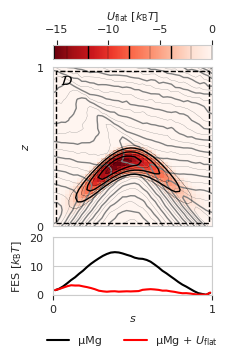

In [24]:
fig, (cax, ax1, ax2) = plt.subplots(nrows=3, height_ratios=[1, 12, 4], figsize=(5.4*cm, 8.7*cm))
ax2.sharex(ax1)
ax2.tick_params(labelbottom=False)

colvar = read_plumed(f'{path}/static.COLVAR')
params = read_wsv(f'{path}/bias_params.wsv').iloc[0]

X_edges = np.linspace(0, 1, 41)
Y_edges = np.linspace(0, 1, 41)
bins = (X_edges, Y_edges)
X_range = edges_to_range(X_edges)
Y_range = edges_to_range(Y_edges)

bias = colvar['metad.bias']  # kJ/mol
weights = np.exp(bias/RT)

# Remove nop == 0
x = colvar['nop']
y = colvar['now']
X = (colvar['nop'] - colvar['now'] + 6) / 2
Y = (colvar['nop'] + colvar['now'] - 6) / 2
weights[X <= 0] = 0
weights[X > 2] = 0
weights[Y <= 0] = 0
weights[Y > 2] = 0

ρ_avg, _, _ = np.histogram2d(X, Y, bins=bins, density=True, weights=weights)
fes = -np.log(ρ_avg)
fes -= finitemin(fes)

extent = [*X_edges[[0, -1]], *Y_edges[[0, -1]]]
levels = np.arange(0, finitemax(fes), 2)

#im = ax1.imshow(fes.T, extent=extent, origin='lower', aspect=1, cmap='RdPu_r')
cf = ax1.contour(fes.T, colors=['gray'], linewidths=[1, 0.2], extent=extent, levels=levels)

# Show bias
XX, YY = np.meshgrid(X_range, Y_range, indexing='ij')
u = bias_fn((XX + YY), YY*2 - (XX + YY) + 6, *params) / RT
im = ax1.imshow(u.T, extent=extent, origin='lower', cmap='Reds_r')
cbar = fig.colorbar(im, cax=cax, orientation='horizontal')
cax.xaxis.tick_top()
cax.xaxis.set_label_position('top')
cf = ax1.contour(u.T, colors=['black'], linewidths=[1, 0.2], linestyles=['solid'], extent=extent, levels=-levels[::-1])
cbar.add_lines(cf)
cbar.set_label("$U_\mathrm{flat}$ [$k_\mathrm{B}T$]")
ε = 0.02
ax1.plot([ε, 1-ε, 1-ε, ε, ε], [ε, ε, 1-ε, 1-ε, ε], color='black', linestyle='dashed', linewidth=1)
ax1.text(2*ε, 1-2*ε, r"$\mathcal{D}$", color='black', size=10, va='top', ha='left')

ax1.xaxis.set_major_locator(MaxNLocator(integer=True))
ax1.yaxis.set_major_locator(MaxNLocator(integer=True))
ax1.tick_params(labelbottom=False)
ax1.set_box_aspect(1)
#ax1.set_xlabel("$s$")
ax1.set_ylabel("$z$")
ax1.grid(False)

# Block analysis for error on FES projection
def get_F_X(data):
    X, Y, weights = np.unstack(data, axis=-1)
    weights = weights / weights.sum()
    ρ_avg, _, _ = np.histogram2d(X, Y, bins=bins, density=True, weights=weights)
    ρ_X = trapezoid(ρ_avg, X_range, axis=1)
    F_X = -np.log(ρ_X)
    F_X -= finitemin(F_X)
    return F_X

data = np.stack([X, Y, weights], axis=-1)
ax2.plot(X_range, get_F_X(data), color='black', label='μMg')
res = block_bootstrap(data, statistic=get_F_X, n_blocks=8)
ax2.fill_between(X_range, res.confidence_interval.low, res.confidence_interval.high, alpha=0.3, facecolor='black')

# Bias weighted
weights = weights * np.exp(-bias_fn(x, y, *params)/RT)
data = np.stack([X, Y, weights], axis=-1)
res = block_bootstrap(np.stack([X, Y, weights], axis=-1), statistic=get_F_X, n_blocks=8)
ax2.plot(X_range, get_F_X(data), color='red', label='μMg + $U_\mathrm{flat}$')
ax2.fill_between(X_range, res.confidence_interval.low, res.confidence_interval.high, alpha=0.3, facecolor='red')

ax2.set_xlabel("$s$", labelpad=-1)
ax2.xaxis.set_ticks_position('bottom')
ax2.xaxis.set_label_position('bottom')
ax2.set_ylabel("FES [$k_\mathrm{B}T$]")
ax2.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.5), ncol=2)
ax2.set_ylim(0, 20)
ax2.set_xlim(0, 1)
fig.get_layout_engine().set(h_pad=0, w_pad=0, hspace=0, wspace=0)

fig.savefig('figures/bias_barrier.pdf')


Unbound: [178280  36580  82730  79840 161150  83700 161440   7360   9300 123260]
Outer: [  3970 155290 176500  34440  80460 174500 167310 132590 172850 173620]
Transition: [ 63860 154020 113760  31630  56580  77030   3290  43910 114860 177680]
Mono: [  1680 194410  63900   4880  67970 186950  97230 175670 170800 184990]
Other mono [180550 180620 181610  90810  90210 181450 181570 180230  11280 180030]
Transition Bi: [ 68790 155690  48930 107080  48990 108090 149710 196080  50420  69340]
Bidentate: [108780 105430 108820 152200 152150 198960 156350  68650 152230 109450]
Other clamp: [10770 40120 10780 89590 41650 92380 42520 94630 89550 10800]


/tmp/ipykernel_4964/4026510573.py:34: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)


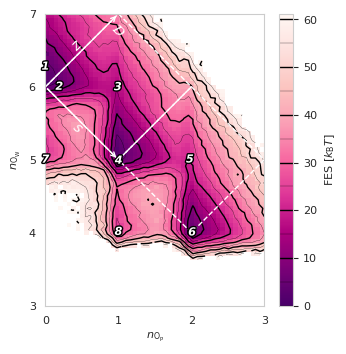

In [8]:
path = PROJECT_DIR / 'metad/triuridine/op_mMg_tip3p'

fig, ax = plt.subplots(figsize=(8.7*cm, 8.7*cm), layout="compressed")

colvar = read_plumed(f'{path}/COLVAR')
bins = np.linspace(0, 3, 51), np.linspace(3, 7, 71)

bias = colvar['metad.bias']  # kJ/mol
weights = np.exp(bias/RT)

# Remove nop == 0
x, y = colvar['nop'], colvar['now']
weights[x <= 0] = 0

# Frames for rendering
def get_frame(*d):
    frames = np.argsort(np.linalg.norm(np.stack(d), axis=0))
    return frames[frames % 10 == 0][:10]
print("Unbound:", get_frame(x > 0, y - 6))
print("Outer:", get_frame(x == 0, y - 6))
print("Transition:", get_frame(x - 1, y - 6))
print("Mono:", get_frame(x - 1, y - 5))
print("Other mono", get_frame(x - 0, y - 5))
print("Transition Bi:", get_frame(x - 2, y - 5))
print("Bidentate:", get_frame(x - 2, y - 4))
print("Other clamp:", get_frame(x - 1, y - 4))

for i, t in enumerate([37000, 80460, 154020, 4880, 155690, 152200, 180550, 10770]):
    txt = ax.text(x[t], y[t], i+1, color='white', fontweight='bold', fontstyle='italic', zorder=10, ha='center', va='center')
    txt.set_path_effects([PathEffects.withStroke(linewidth=2, foreground='k')])


ρ_avg, x_edges, y_edges = np.histogram2d(x, y, bins=bins, density=True, weights=weights)
fes = -np.log(ρ_avg)
fes -= finitemin(fes)

extent = [*x_edges[[0, -1]], *y_edges[[0, -1]]]
levels = np.arange(0, finitemax(fes), 5)

im = ax.imshow(fes.T, extent=extent, origin='lower', aspect=1, cmap='RdPu_r')
cf = ax.contour(fes.T, colors=['black'], linewidths=[1, 0.2], extent=extent, levels=levels)
cbar = plt.colorbar(im)
cbar.add_lines(cf)
cbar.set_label("FES [$k_\mathrm{B}T$]")

ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(False)
ax.plot([0, 1, 2, 1, 0], [6, 7, 6, 5, 6], color='white', linestyle='dashed', linewidth=1)
ax.plot([1, 2, 3, 2, 1], [5, 6, 5, 4, 5], color='white', linestyle='dashed', linewidth=1)
ax.annotate("", xy=(1, 5), xytext=(0, 6), color='white', zorder=20, arrowprops=dict(arrowstyle="->"))
ax.annotate("", xy=(1, 7), xytext=(0, 6), color='white', zorder=20, arrowprops=dict(arrowstyle="->"))
ax.text(0.5, 5.5, r'$s$', rotation=-45, color='white', size=10, va='top', ha='center', rotation_mode='anchor')
ax.text(0.5, 6.5, r'$z$', rotation=45, color='white', size=10, va='bottom', ha='center', rotation_mode='anchor')
ax.text(1, 6.9, r'$\mathcal{D}$', rotation=-45, color='white', size=10, va='top', ha='left', rotation_mode='anchor')


ax.set_xlabel("$n_\mathrm{O_P}$")
ax.set_ylabel("$n_\mathrm{O_W}$")

fig.savefig('figures/triuridine_metad_fes.pdf')

/tmp/ipykernel_4964/2156478543.py:27: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)


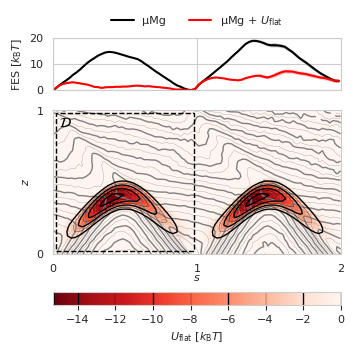

In [9]:
fig, (ax2, ax1, cax) = plt.subplots(nrows=3, height_ratios=[4, 12, 1], figsize=(8.7*cm, 8.7*cm))
ax2.sharex(ax1)
ax2.tick_params(labelbottom=False)
colvar = read_plumed(f'{path}/static.COLVAR')
params = read_wsv(f'{path}/bias_params.wsv').iloc[0]

X_edges = np.linspace(0, 2, 81)
Y_edges = np.linspace(0, 1, 41)
bins = (X_edges, Y_edges)
X_range = edges_to_range(X_edges)
Y_range = edges_to_range(Y_edges)

bias = colvar['metad.bias']  # kJ/mol
weights = np.exp(bias/RT)

# Remove nop == 0
x = colvar['nop']
y = colvar['now']
X = (colvar['nop'] - colvar['now'] + 6) / 2
Y = (colvar['nop'] + colvar['now'] - 6) / 2
weights[X <= 0] = 0
weights[X > 4] = 0
weights[Y <= 0] = 0
weights[Y > 2] = 0

ρ_avg, _, _ = np.histogram2d(X, Y, bins=bins, density=True, weights=weights)
fes = -np.log(ρ_avg)
fes -= finitemin(fes)

extent = [*X_edges[[0, -1]], *Y_edges[[0, -1]]]
levels = np.arange(0, finitemax(fes), 2)

#im = ax1.imshow(fes.T, extent=extent, origin='lower', aspect=1, cmap='RdPu_r')
cf = ax1.contour(fes.T, colors=['gray'], linewidths=[1, 0.2], extent=extent, levels=levels)

# Show bias
XX, YY = np.meshgrid(X_range, Y_range, indexing='ij')
u = bias_fn((XX + YY), YY*2 - (XX + YY) + 6, *params) / RT
im = ax1.imshow(u.T, extent=extent, origin='lower', cmap='Reds_r')
cbar = fig.colorbar(im, cax=cax, orientation='horizontal')
cf = ax1.contour(u.T, colors=['black'], linewidths=[1, 0.2], linestyles=['solid'], extent=extent, levels=-levels[::-1])
cbar.add_lines(cf)
cbar.set_label("$U_\mathrm{flat}$ [$k_\mathrm{B}T$]")
ε = 0.02
ax1.plot([ε, 1-ε, 1-ε, ε, ε], [ε, ε, 1-ε, 1-ε, ε], color='black', linestyle='dashed', linewidth=1)
ax1.text(2*ε, 1-2*ε, r"$\mathcal{D}$", color='black', size=10, va='top', ha='left')

ax1.xaxis.set_major_locator(MaxNLocator(integer=True))
ax1.yaxis.set_major_locator(MaxNLocator(integer=True))
ax1.tick_params(labelbottom=True)
ax1.set_xlabel("$s$", labelpad=-1)
ax1.set_ylabel("$z$")
ax1.grid(False)

# Block analysis for error on FES projection
def get_F_X(data):
    X, Y, weights = np.unstack(data, axis=-1)
    weights = weights / weights.sum()
    ρ_avg, _, _ = np.histogram2d(X, Y, bins=bins, density=True, weights=weights)
    ρ_X = trapezoid(ρ_avg, Y_range, axis=1)
    F_X = -np.log(ρ_X)
    F_X -= finitemin(F_X)
    return F_X

data = np.stack([X, Y, weights], axis=-1)
ax2.plot(X_range, get_F_X(data), color='black', label='μMg')
res = block_bootstrap(data, statistic=get_F_X, n_blocks=8)
ax2.fill_between(X_range, res.confidence_interval.low, res.confidence_interval.high, alpha=0.3, facecolor='black')

# Bias weighted
weights = weights * np.exp(-bias_fn(x, y, *params)/RT)
data = np.stack([X, Y, weights], axis=-1)
res = block_bootstrap(np.stack([X, Y, weights], axis=-1), statistic=get_F_X, n_blocks=8)
ax2.plot(X_range, get_F_X(data), color='red', label='μMg + $U_\mathrm{flat}$')
ax2.fill_between(X_range, res.confidence_interval.low, res.confidence_interval.high, alpha=0.3, facecolor='red')

#ax2.set_xlabel("$s$", labelpad=1)
ax2.set_ylabel("FES [$k_\mathrm{B}T$]")
ax2.legend(frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1), ncol=2)
ax2.set_ylim(0, 20)
ax2.set_xlim(0, 2)


fig.savefig('figures/triuridine_bias_barrier.pdf')
